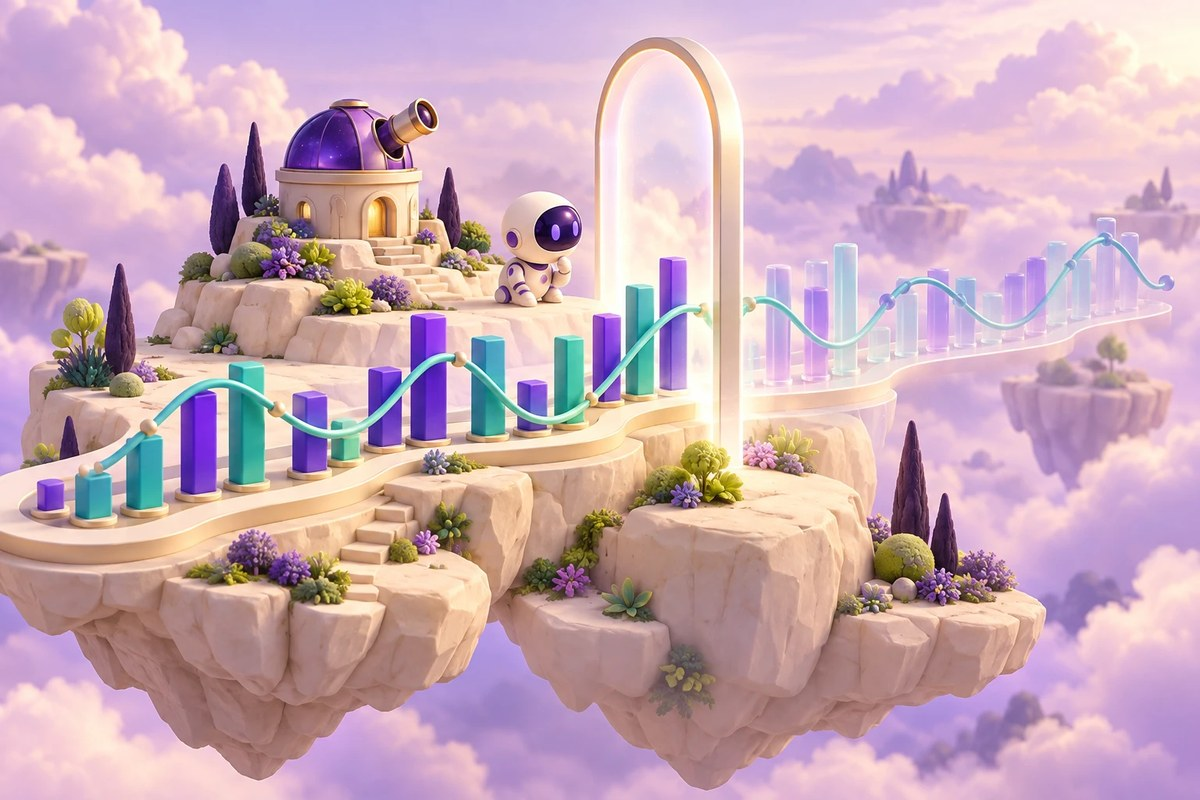

AI PATH · Временные ряды · Урок 050

# Трафик компании: первый временной прогноз

Короткий опыт с генератором окон и Conv1D

**Архивный учебный материал.** Код и сохранённые результаты относятся к исходному ноутбуку. Оформление не означает новый запуск или подтверждение старых метрик. Перед выполнением проверьте зависимости и ограничения.

<a id="ai-050-goal"></a>
## Что вы разберёте

Проследить минимальную цепочку от загрузки ряда трафика до обучения и вызова проверки свёрточного прогноза.

### Перед началом

- Базовые функции Python
- Понятие временного окна

### Что понадобится

- terra_ai==0.0.0.34 и модуль терра_ии
- Набор ТРАФИК, получаемый загрузчиком библиотеки
- Совместимая среда с ресурсами для Conv1D на 1024 фильтра

## Навигация по уроку

- [Цель и подготовка](#ai-050-goal)
- [Карта урока](#ai-050-map)
- [Готовим историческую библиотеку](#ai-050-section-01)
- [Загружаем временной ряд](#ai-050-section-02)
- [Смотрим на генераторы](#ai-050-section-03)
- [Обучение и проверка прогноза](#ai-050-section-04)
- [Проверьте понимание](#ai-050-practice)
- [Источники и ограничения](#ai-050-provenance)

<a id="ai-050-map"></a>
## Карта урока

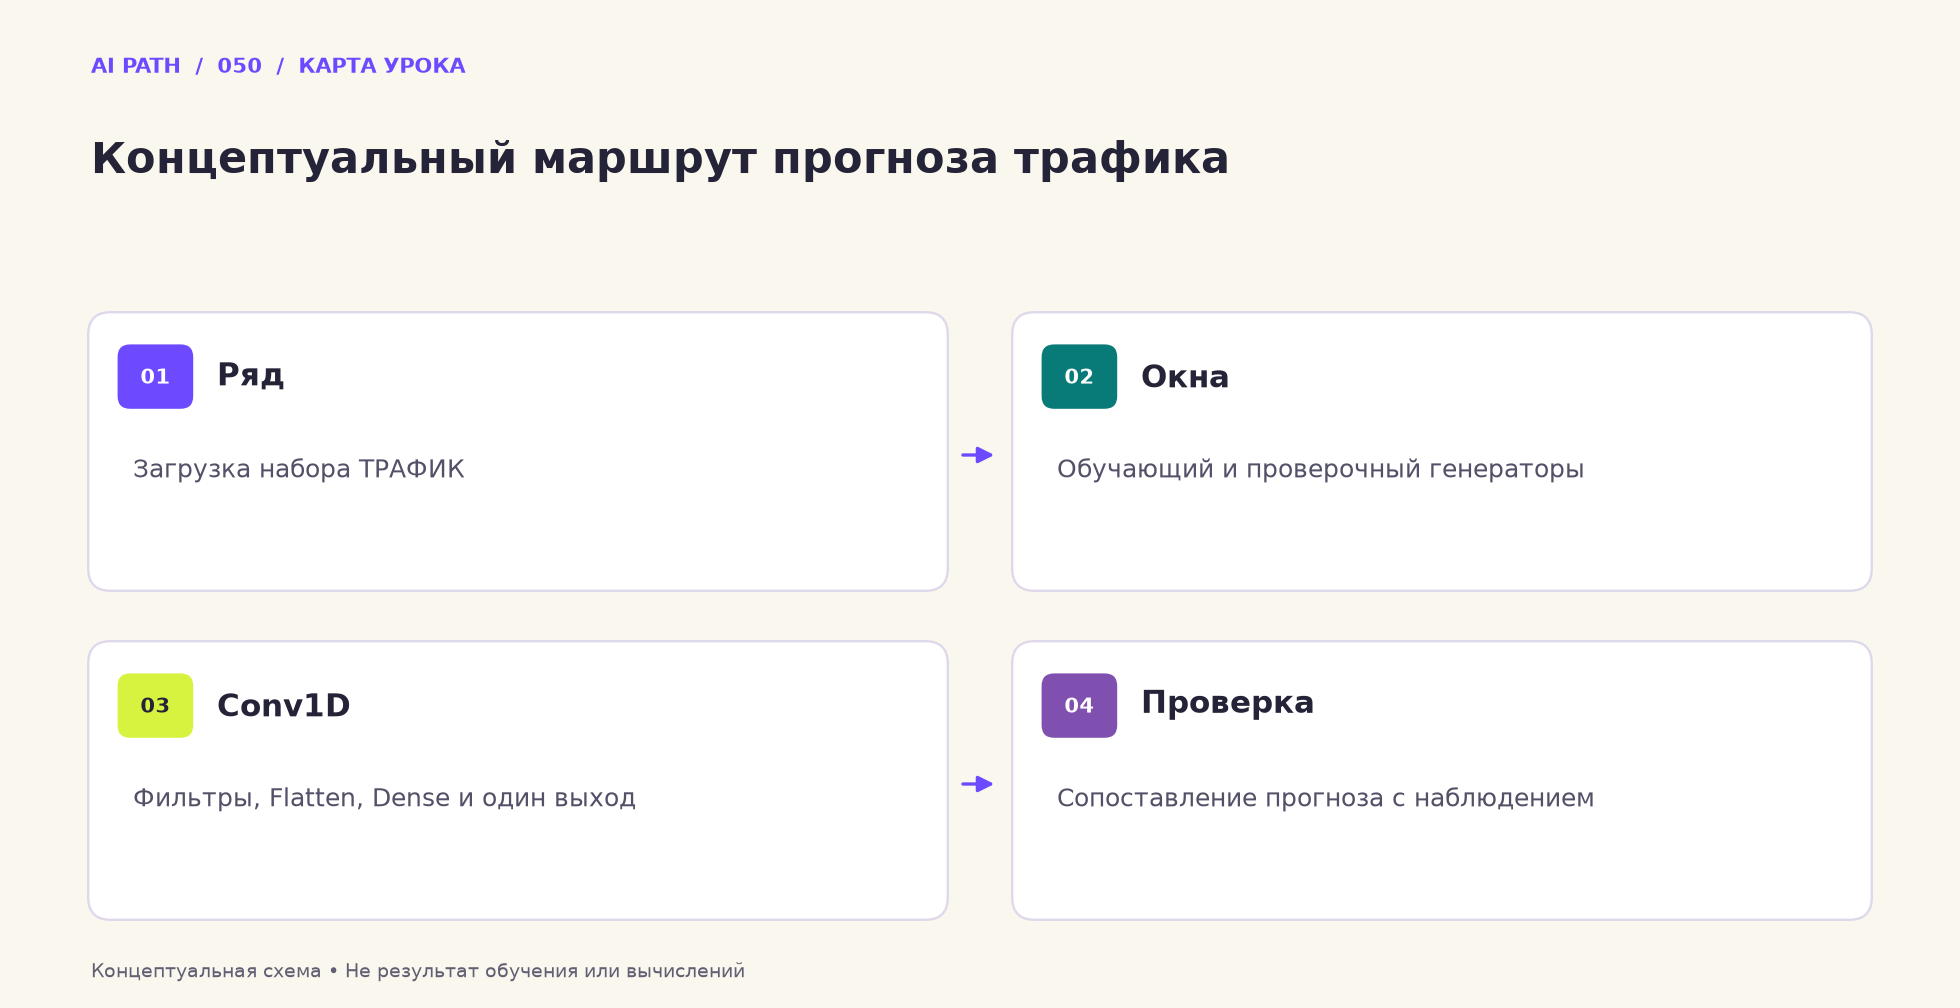

Схема показывает последовательность идей. Она не содержит результатов нового обучения или вычислений.

1. **Ряд** — Загрузка набора ТРАФИК
2. **Окна** — Обучающий и проверочный генераторы
3. **Conv1D** — Фильтры, Flatten, Dense и один выход
4. **Проверка** — Сопоставление прогноза с наблюдением

<a href="https://colab.research.google.com/github/safal207/hello-world/blob/master/%D0%A2%D1%80%D0%B0%D1%84%D0%B8%D0%BA_%D0%BA%D0%BE%D0%BC%D0%BF%D0%B0%D0%BD%D0%B8%D0%B8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<a id="ai-050-section-01"></a>
## 01 · Готовим историческую библиотеку

Версия пакета зафиксирована в исходнике. Перед обучением нужно подтвердить, что пакет устанавливается и предоставляет используемые функции.

_Далее — исходные ячейки учебного материала._

In [1]:
#Установить terra_ai
!pip install terra_ai==0.0.0.34
#Импортировать модуль терра_ии
from terra_ai import терра_ии

Все нобходимые библиотеки установлены и готовы к работе


<a id="ai-050-section-02"></a>
## 02 · Загружаем временной ряд

Выясните единицы и порядок наблюдений набора ТРАФИК; название набора не описывает его качество или актуальность.

_Далее — исходные ячейки учебного материала._

In [2]:
# Загружаем базу трафик
терра_ии.загрузить_базу('ТРАФИК', справка=True)

Загрузка данных завершена 

Загружена база трафика компании



<a id="ai-050-section-03"></a>
## 03 · Смотрим на генераторы

Функция возвращает обучающий генератор, проверочный генератор и данные. Проверьте форму одного окна и временное разделение.

_Далее — исходные ячейки учебного материала._

In [4]:
# Создаем выборки для обучения нейронной сети
обучающий_генератор, тестовый_генератор, данные = терра_ии.создать_выборки_трафик()

Выборки созданы успешно


<a id="ai-050-section-04"></a>
## 04 · Обучение и проверка прогноза

Conv1D с 1024 фильтрами и Dense на 1024 элемента завершается одним выходом. 40 эпох — настройка опыта, а не доказательство качества.

_Далее — исходные ячейки учебного материала._

Создана модель нейронной сети!
Instructions for updating:
Please use Model.fit, which supports generators.
Эпоха №1  Время обучения: 21.8c  Ошибка на обучающей выборке: 0.03055        Ошибка на прверочной выборке: 0.01987
Эпоха №2  Время обучения: 20.34c Ошибка на обучающей выборке: 0.02479        Ошибка на прверочной выборке: 0.00592
Эпоха №3  Время обучения: 20.25c Ошибка на обучающей выборке: 0.01148        Ошибка на прверочной выборке: 0.00533
Эпоха №4  Время обучения: 20.2c  Ошибка на обучающей выборке: 0.00699        Ошибка на прверочной выборке: 0.00345
Эпоха №5  Время обучения: 19.83c Ошибка на обучающей выборке: 0.00665        Ошибка на прверочной выборке: 0.00583
Эпоха №6  Время обучения: 19.64c Ошибка на обучающей выборке: 0.00421        Ошибка на прверочной выборке: 0.00524
Эпоха №7  Время обучения: 20.01c Ошибка на обучающей выборке: 0.00393        Ошибка на прверочной выборке: 0.00261
Эпоха №8  Время обучения: 19.54c Ошибка на обучающей выборке: 0.0047         Ошибка на п

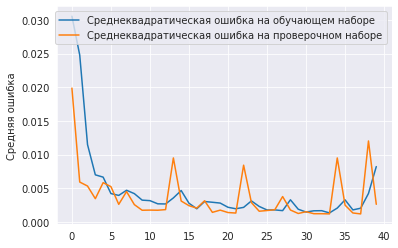

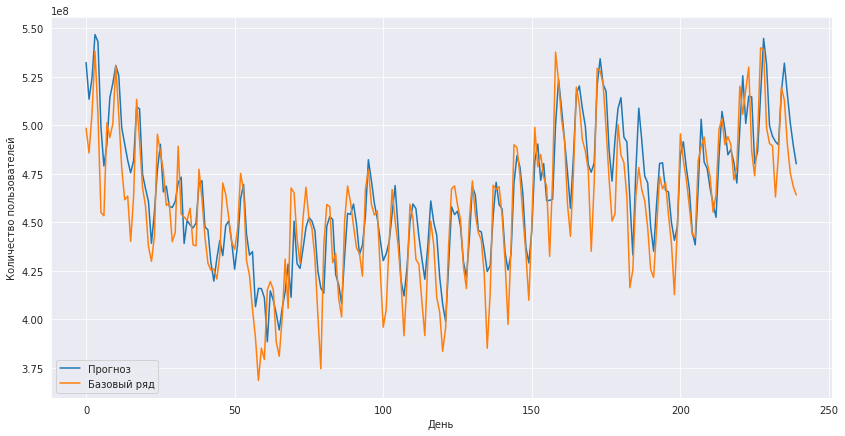

In [5]:
# Создаем нейронную сеть

слои = 'Сверточный1D-1024 Выравнивающий Полносвязный-1024 Полносвязный-1'

# создание модели
нейронка = терра_ии.создать_сеть(слои = слои,
                                 задача = 'трафик')
# Обучаем модель
терра_ии.обучение_модели_трафик(нейронка,
    обучающий_генератор, тестовый_генератор,        
    количество_эпох = 40)

терра_ии.тест_модели_трафика(нейронка, данные)

<a id="ai-050-practice"></a>
## Проверьте понимание

1. Как выглядит один пример из train_gen и какое наблюдение является его целью?
2. Сохраняет ли генератор хронологический порядок между обучением и проверкой?
3. Почему нужно сравнить сеть с последним известным значением ряда?

### Один самостоятельный эксперимент

Сравните исходные 1024 фильтра с меньшим числом при неизменных данных и числе эпох; отдельно сохраните время обучения и общую ошибку.

**Критерий успеха:** Выборки совпадают, метрика одна и та же, а ресурсы и ошибка записаны отдельно без предположения, что большая сеть обязательно лучше.

<a id="ai-050-provenance"></a>
## Источники и ограничения

[Исходный ноутбук и его авторские материалы](https://github.com/safal207/students/blob/d848e04c8f8d6e3e8e42ce15fbd98c00612e0e17/Trafic/%D0%A2%D1%80%D0%B0%D1%84%D0%B8%D0%BA_%D0%BA%D0%BE%D0%BC%D0%BF%D0%B0%D0%BD%D0%B8%D0%B8.ipynb) · репозиторий `safal207/students`.

Исходные подписи, ссылки, авторство, код, изображения и аудио сохранены. Длинные текстовые выводы могут быть сокращены с указанием источника. Архивные результаты не пересчитывались.

### Перед новым запуском

- Набор находится за внешним загрузчиком старой Terra AI и не встроен в ноутбук.
- Размер окна и правила разделения скрыты внутри библиотеки; их нужно установить до интерпретации проверки.
- Обучение повторно не выполнялось; модель с 1024 фильтрами может требовать существенных ресурсов.

**Иллюстрации:** обложка направления AI PATH; карта урока подготовлена по содержимому исходных ячеек.